# Kitagawa model: unscented vs particle filter

This notebook runs two filters on the nonlinear Kitagawa benchmark (scalar, 1D) and compares them:

- the **unscented Kalman filter** (UKF), a Gaussian filter that keeps a mean and a variance;
- the **bootstrap particle filter** (PF), a sequential Monte Carlo method that keeps a weighted set of samples.

It produces the figures and the RMSE table used in the *Numerical Comparison* section of the thesis. The extended Kalman filter and the grid filter are left out on purpose. Run top to bottom (*Kernel -> Restart & Run All*); all outputs go to `figures/`.

## The model

The state and observation follow the standard Kitagawa benchmark:

$$X_k = \frac{X_{k-1}}{2} + \frac{25\,X_{k-1}}{1 + X_{k-1}^2} + 8\cos(1.2\,k) + w_k, \qquad w_k \sim \mathcal{N}(0, Q),$$

$$y_k = \frac{X_k^2}{20} + v_k, \qquad v_k \sim \mathcal{N}(0, R).$$

The observation is even, so it cannot tell $x$ from $-x$, and the conditional law is often bimodal. A single-Gaussian UKF may therefore switch abruptly between compromises or ignore an observation when the predicted mean is near zero. Parameters: $Q = 10$, $R = 1$, $X_0 \sim \mathcal{N}(0, 5)$, horizon $60$ steps, $N = 10^4$ particles; the RMSE table averages over $50$ independent realizations.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from scipy.special import logsumexp

# --- Model and experiment parameters ---
N_STEPS     = 60
X0_MEAN     = 0.0
X0_VAR      = 5.0
Q, R        = 10.0, 1.0
N_PARTICLES = 10000
BASE_SEED   = 20260714   # representative realization for the trajectory plots
M_SEEDS     = 50         # independent realizations for the RMSE table
N_TRAJ      = 80         # trajectories in the state-trajectory plot

COLORS = {"truth": "black", "obs": "gray", "traj": "steelblue",
          "ukf": "tab:green", "pf": "tab:red"}

FIGURE_DIR = Path("figures")
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

# Standard Kitagawa benchmark. Use the same index k in simulation and filtering.
def f(x, k):
    return 0.5*x + 25.0*x/(1.0 + x*x) + 8.0*np.cos(1.2*k)

def h(x):
    return x*x/20.0

def savefig(name):
    plt.tight_layout()
    plt.savefig(FIGURE_DIR/name, bbox_inches="tight")
    plt.show()
    print("saved", FIGURE_DIR/name)


## Filters

Three helper functions set up the experiment. `simulate(seed)` draws one realization of the state and its observations. `run_ukf(y)` runs the scalar unscented filter with three sigma points. `run_pf(rng, y)` runs the bootstrap particle filter with systematic resampling at every step.

The old setting `alpha=0.35` produced a central mean weight near $-7.16$ and two weights near $4.08$. Those large cancellations are fragile for Kitagawa's strongly nonlinear transition. Here `alpha=1` gives nonnegative mean weights; `beta=2` retains the Gaussian fourth-moment correction needed by the quadratic observation.

In [2]:
# One realization of the Kitagawa model: returns (rng, x_true, y)
def simulate(seed):
    rng = np.random.default_rng(seed)
    x = np.empty(N_STEPS+1)
    y = np.full(N_STEPS+1, np.nan)
    x[0] = rng.normal(X0_MEAN, np.sqrt(X0_VAR))
    for k in range(1, N_STEPS+1):
        x[k] = f(x[k-1], k) + rng.normal(0, np.sqrt(Q))
        y[k] = h(x[k]) + rng.normal(0, np.sqrt(R))
    return rng, x, y

# Scalar scaled UKF (three sigma points). Diagnostics explain abrupt corrections.
def run_ukf(y, return_diagnostics=False):
    # alpha=1 avoids the large cancelling weights created by alpha=0.35.
    alpha, beta, kappa = 1.0, 2.0, 0.0
    lam = alpha**2*(1+kappa) - 1
    Wm = np.array([lam/(1+lam), 1/(2*(1+lam)), 1/(2*(1+lam))])
    Wc = Wm.copy(); Wc[0] += 1 - alpha**2 + beta

    def sigma_points(mean, variance):
        spread = np.sqrt(max((1+lam)*variance, 1e-14))
        return np.array([mean, mean+spread, mean-spread])

    m = np.empty(N_STEPS+1); P = np.empty(N_STEPS+1)
    gain = np.full(N_STEPS+1, np.nan)
    innovation = np.full(N_STEPS+1, np.nan)
    m[0], P[0] = X0_MEAN, X0_VAR

    for k in range(1, N_STEPS+1):
        # Prediction through the Kitagawa transition.
        x_sigma = sigma_points(m[k-1], P[k-1])
        x_prop = f(x_sigma, k)
        m_pred = Wm @ x_prop
        P_pred = Wc @ ((x_prop-m_pred)**2) + Q

        # Re-form sigma points from N(m_pred,P_pred). This includes process
        # noise Q before applying the nonlinear measurement h(x)=x^2/20.
        x_pred_sigma = sigma_points(m_pred, P_pred)
        z_sigma = h(x_pred_sigma)
        z_pred = Wm @ z_sigma
        S = Wc @ ((z_sigma-z_pred)**2) + R
        Cxz = Wc @ ((x_pred_sigma-m_pred)*(z_sigma-z_pred))

        gain[k] = Cxz/S
        innovation[k] = y[k]-z_pred
        m[k] = m_pred + gain[k]*innovation[k]
        P[k] = max(P_pred - gain[k]**2*S, 1e-10)

    if return_diagnostics:
        return m, P, gain, innovation
    return m

# Bootstrap particle filter, systematic resampling every step.
# Returns (mean, q05, q95) tracks.
def run_pf(rng, y, n=N_PARTICLES):
    def systematic_resample(w, rng):
        u = (rng.random() + np.arange(len(w)))/len(w)
        return np.searchsorted(np.cumsum(w), u)
    part = rng.normal(X0_MEAN, np.sqrt(X0_VAR), n)
    m = np.empty(N_STEPS+1); q05 = np.empty(N_STEPS+1); q95 = np.empty(N_STEPS+1)
    m[0] = part.mean(); q05[0], q95[0] = np.quantile(part, [.05, .95])
    for k in range(1, N_STEPS+1):
        part = f(part, k) + rng.normal(0, np.sqrt(Q), n)
        logw = -0.5*(y[k]-h(part))**2/R
        w = np.exp(logw - logsumexp(logw))
        m[k] = w@part
        order = np.argsort(part); cs = np.cumsum(w[order]); ps = part[order]
        q05[k], q95[k] = np.interp([.05, .95], cs, ps)
        part = part[systematic_resample(w, rng)]
    return m, q05, q95


## Multi-seed RMSE table

Each seed gives an independent realization. For each filter we compute the RMSE of its mean estimate against the true state over the horizon, then average over the seeds. The table (mean and standard deviation) is printed and written to `figures/kitagawa_rmse.csv`.

In [3]:
import csv

def rmse(est, truth):
    return np.sqrt(np.mean((est[1:] - truth[1:])**2))

ukf_r = np.empty(M_SEEDS); pf_r = np.empty(M_SEEDS)
for j, s in enumerate(range(BASE_SEED, BASE_SEED + M_SEEDS)):
    rng_j, x_j, y_j = simulate(s)
    ukf_r[j] = rmse(run_ukf(y_j), x_j)
    pf_m_j, _, _ = run_pf(rng_j, y_j)
    pf_r[j] = rmse(pf_m_j, x_j)

print("RMSE over", M_SEEDS, "seeds (mean +/- std), N =", N_PARTICLES, "particles:")
print("  UKF                : %.3f +/- %.3f" % (ukf_r.mean(), ukf_r.std()))
print("  bootstrap particle : %.3f +/- %.3f" % (pf_r.mean(), pf_r.std()))

with open(FIGURE_DIR/"kitagawa_rmse.csv", "w", newline="") as fh:
    wtr = csv.writer(fh)
    wtr.writerow(["filter", "mean_rmse", "std_rmse", "n_seeds", "n_particles"])
    wtr.writerow(["ukf", "%.4f" % ukf_r.mean(), "%.4f" % ukf_r.std(), M_SEEDS, N_PARTICLES])
    wtr.writerow(["pf",  "%.4f" % pf_r.mean(),  "%.4f" % pf_r.std(),  M_SEEDS, N_PARTICLES])
print("saved", FIGURE_DIR/"kitagawa_rmse.csv")


RMSE over 50 seeds (mean +/- std), N = 10000 particles:
  UKF                : 7.646 +/- 0.434
  bootstrap particle : 4.542 +/- 0.834
saved figures/kitagawa_rmse.csv


## Representative-realization figures

One realization (`BASE_SEED`) drives four figures:

- `kitagawa_trajectories.pdf`: several state paths, showing the two-sided dynamics;
- `kitagawa_truth_obs.pdf`: the hidden state and its observations, showing the sign ambiguity;
- `kitagawa_errors.pdf`: the estimation errors of the two filters;
- `kitagawa_overlay.pdf`: the state with the UKF and PF means and the PF band.

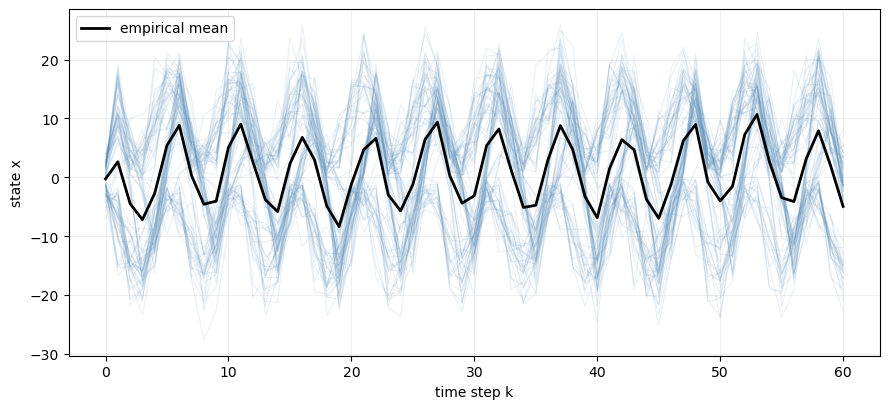

saved figures/kitagawa_trajectories.pdf


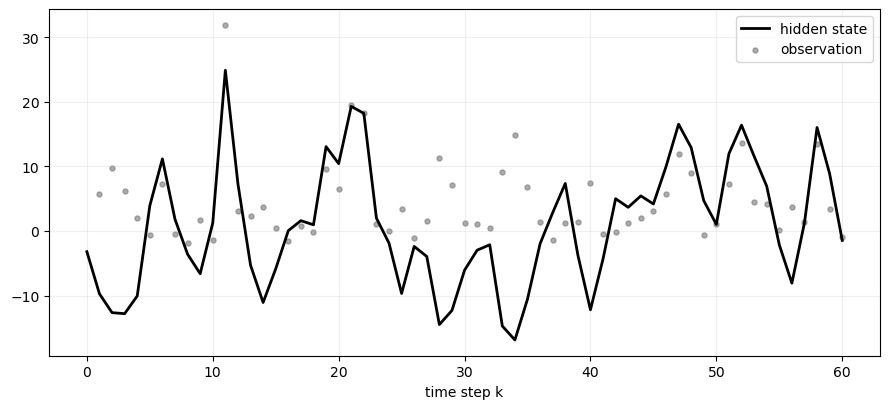

saved figures/kitagawa_truth_obs.pdf


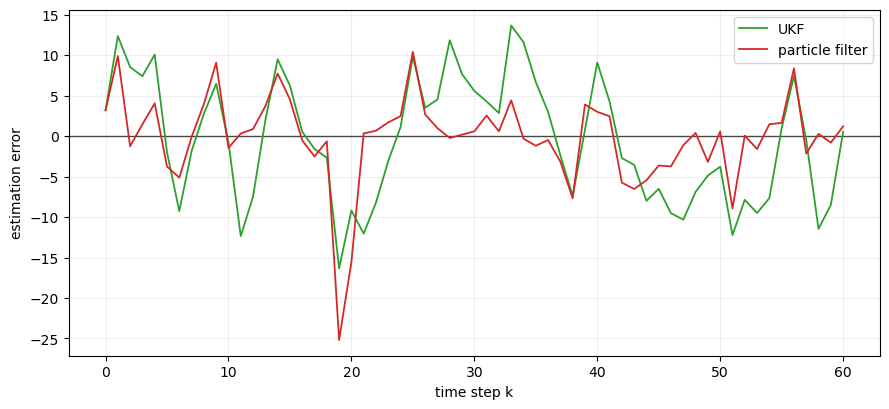

saved figures/kitagawa_errors.pdf


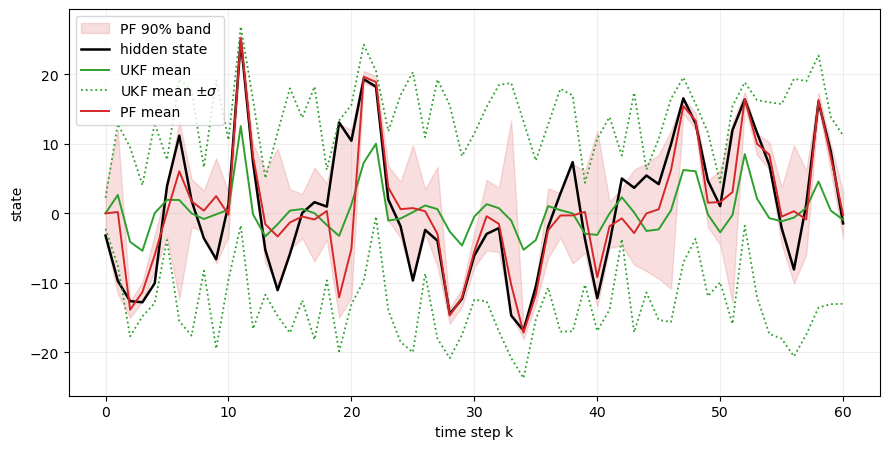

saved figures/kitagawa_overlay.pdf


In [4]:
# Representative realization
rng0, x0, y0 = simulate(BASE_SEED)
ukf0, ukf0_P, _, _ = run_ukf(y0, return_diagnostics=True)
pf0, pf0_lo, pf0_hi = run_pf(rng0, y0)
t = np.arange(N_STEPS+1)

# (a) Several state trajectories (unconditioned dynamics)
rng_t = np.random.default_rng(BASE_SEED)
paths = np.empty((N_TRAJ, N_STEPS+1))
paths[:, 0] = rng_t.normal(X0_MEAN, np.sqrt(X0_VAR), N_TRAJ)
for k in range(1, N_STEPS+1):
    paths[:, k] = f(paths[:, k-1], k) + rng_t.normal(0, np.sqrt(Q), N_TRAJ)
plt.figure(figsize=(9, 4.2))
for p in paths:
    plt.plot(t, p, color=COLORS["traj"], alpha=0.12, lw=0.8)
plt.plot(t, paths.mean(0), color=COLORS["truth"], lw=2, label="empirical mean")
plt.xlabel("time step k"); plt.ylabel("state x"); plt.legend(); plt.grid(alpha=.2)
savefig("kitagawa_trajectories.pdf")

# (b) Hidden state and nonlinear observations
plt.figure(figsize=(9, 4.2))
plt.plot(t, x0, color=COLORS["truth"], lw=2, label="hidden state")
plt.scatter(t[1:], y0[1:], color=COLORS["obs"], s=13, alpha=.65, label="observation")
plt.xlabel("time step k"); plt.legend(); plt.grid(alpha=.2)
savefig("kitagawa_truth_obs.pdf")

# (c) Estimation errors, UKF vs particle filter
plt.figure(figsize=(9, 4.2))
plt.axhline(0, color=COLORS["truth"], lw=1, alpha=.7)
plt.plot(t, ukf0 - x0, color=COLORS["ukf"], lw=1.3, label="UKF")
plt.plot(t, pf0 - x0, color=COLORS["pf"], lw=1.3, label="particle filter")
plt.xlabel("time step k"); plt.ylabel("estimation error"); plt.legend(); plt.grid(alpha=.2)
savefig("kitagawa_errors.pdf")

# (d) Overlay: truth, UKF mean +/- one standard deviation, PF mean and 90% band
plt.figure(figsize=(9, 4.6))
plt.fill_between(t, pf0_lo, pf0_hi, color=COLORS["pf"], alpha=.15, label="PF 90% band")
plt.plot(t, x0, color=COLORS["truth"], lw=1.8, label="hidden state")
plt.plot(t, ukf0, color=COLORS["ukf"], lw=1.4, label="UKF mean")
ukf0_sigma = np.sqrt(ukf0_P)
plt.plot(t, ukf0 + ukf0_sigma, color=COLORS["ukf"], ls=":", lw=1.3, label=r"UKF mean $\pm\sigma$")
plt.plot(t, ukf0 - ukf0_sigma, color=COLORS["ukf"], ls=":", lw=1.3)
plt.plot(t, pf0, color=COLORS["pf"], lw=1.4, label="PF mean")
plt.xlabel("time step k"); plt.ylabel("state"); plt.legend(); plt.grid(alpha=.2)
savefig("kitagawa_overlay.pdf")
